<a href="https://colab.research.google.com/github/adrian-lo-te/Sprints/blob/main/Sprints/Sprint%208/%20Sprint_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**IMPORTACIONS**

In [ ]:
import pandas as pd
import numpy as np
import json
import os
import unicodedata
import seaborn as sns
import matplotlib.pyplot as plt
import re
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

**CÀRREGA D'ARXIUS**

In [ ]:
complex_xls = "sprint8_complex.xlsx"

try:
    complex = pd.ExcelFile(complex_xls)
except FileNotFoundError:
    from google.colab import drive
    drive.mount('/content/drive')
    ruta_complex = '/content/drive/MyDrive/csv colab/sprint8_complex.xlsx'
    complex = pd.ExcelFile(ruta_complex)

matrius_xls = "matriu_distancies.xlsx"

try:
    matrius = pd.ExcelFile(matrius_xls)
except FileNotFoundError:
    from google.colab import drive
    drive.mount('/content/drive')
    ruta_matrius = '/content/drive/MyDrive/csv colab/matriu_distancies.xlsx'
    matrius = pd.ExcelFile(ruta_matrius)

politica_json = "politica_salarial.json"

try:
    with open(politica_json, encoding="utf-8") as fitxer_json:
        politica = json.load(fitxer_json)
except FileNotFoundError:
    from google.colab import drive
    drive.mount('/content/drive')
    ruta_politica = '/content/drive/MyDrive/csv colab/politica_salarial.json'
    with open(ruta_politica, encoding="utf-8") as fitxer_json:
        politica = json.load(fitxer_json)

ciutats_csv = "ciutats_context.csv"

try:
    ciutats = pd.read_csv(ciutats_csv, encoding='latin1')
except FileNotFoundError:
    from google.colab import drive
    drive.mount('/content/drive')
    ruta_ciutats = '/content/drive/MyDrive/csv colab/ciutats_context.csv'
    ciutats = pd.read_csv(ruta_ciutats, encoding='latin1')

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Nivell 1 - EDA estructurat i neteja bàsica**

Tenim un dataset d'empleats obtingut a partir d'una enquesta interna. Abans de poder extreure conclusions, cal assegurar-nos que les dades són correctes, consistents i analitzables.

### **Exercici 1: Exploració inicial del dataset**

🎯 **Objectiu:** entendre l’estructura general del dataset i detectar possibles problemes abans de començar a netejar o transformar dades.
En aquest exercici has de realitzar una exploració inicial del DataFrame (sprint8_complex.xlsx) per respondre, com a mínim, a les següents preguntes:

  **»** Quantes files i columnes té el dataset?
  
  **»** Quin tipus de dades conté cada columna?
  
  **»** Hi ha files duplicades?
  
  **»** Les dades semblen coherents a primera vista?
  
  **»** Detectes possibles problemes o inconsistències evidents?

Per fer-ho, hauràs de:

  **»** Analitzar les dimensions del dataset
  
  **»** Mostrar una mostra representativa de files
  
  **»** Revisar els tipus de variables
  
  **»** Les dades semblen coherents a primera vista?
  
  **»** Detectar files duplicades
  
  **»** Identificar i descriure possibles problemes inicials (sense solucionar-los encara)


 **Important!** acompanya el codi amb un breu comentari explicant què has observat i quins problemes creus que caldrà abordar en els exercicis següents.

In [ ]:
dades_c = pd.read_excel(complex, sheet_name=complex.sheet_names[0], skiprows=3, index_col = 0)

print(f"Dimensions del conjunt de dades: {dades_c.shape[0]} files i {dades_c.shape[1]} columnes.")

print("\nTipus de dades i columnes:")
print(dades_c.dtypes)

duplicats = dades_c.duplicated().sum()
print(f"\nNombre de files duplicades exactes: {duplicats}")
display(dades_c)

Dimensions del conjunt de dades: 1007 files i 19 columnes.

Tipus de dades i columnes:
Nom                            object
Cognoms                        object
DNI                            object
País d'origen                  object
Ciutat                         object
Dia de Naixement              float64
Mes de Naixement              float64
Any de Naixement              float64
Gènere                         object
Salari mensual                 object
Fills                          object
No Fills                       object
Grup Professional              object
CÃ rrec                        object
Nombre_fills                  float64
Te_cotxe                       object
Km_anuals                     float64
Consum_mitja_L_100km          float64
Temperatura_mitjana_ciutat    float64
dtype: object

Nombre de files duplicades exactes: 4


,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,CÃ rrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23.0,3.0,1958.0,Dona,"1,469 â‚¬",True,NaN,Grup B,Cap de projecte,3.0,True,32108.0,25.0,10.1
1,Marc,MuÃ±oz,48840994W,Espanya,Alacant,8.0,11.0,1960.0,H,"2,718 â‚¬",NaN,True,Grup C,Senior analyst,0.0,True,19496.0,10.4,18.7
2,Noa,Serra,14308421X,Espanya,Alacant,27.0,4.0,1961.0,D,1358 euros,True,NaN,Grup A,TÃ¨cnic IT,4.0,NaN,NaN,NaN,16.7
3,Pol,Gil,58586340F,Espanya,Sevilla,13.0,10.0,1985.0,H,"1,478 â‚¬",True,NaN,Grup B,Data Analyst,2.0,False,NaN,NaN,18.3
4,David,Vila,82070937P,Espanya,Bilbao,29.0,11.0,1965.0,Dona,"1,284 â‚¬",NaN,True,Grup B,Administratiu,NaN,True,NaN,11.8,13.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1002,Alba,MuÃ±oz,97954019T,Espanya,Bilbao,25.0,10.0,1983.0,D,"1,409 â‚¬",NaN,True,Grup B,Responsable de vendes,0.0,NaN,NaN,NaN,14.7
1003,Claudia,Gil Ferrer,55297384F,Espanya,ValÃ¨ncia,1.0,11.0,1981.0,H,1.789 â‚¬,NaN,True,Grup B,Responsable de vendes,0.0,True,29952.0,9.2,20.3
1004,Oriol,Ferrer,52590001R,Espanya,Zaragoza,15.0,7.0,1973.0,D,786â‚¬,NaN,True,Grup A,Analista,0.0,True,81381.0,6.5,13.9
1005,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Per començar, he llegit la primera fulla mitjançant pd.read_excel(), saltant-me les tres primeres files de capçalera (skiprows=3) i assignant la primera columna restant com a índex. Seguidament, he imprès les dimensions del DataFrame (dades_c.shape) per veure exactament quantes files i columnes té, i he revisat els tipus de dades de cada columna amb .dtypes. També he comprovat el nombre de files duplicades exactes utilitzant .duplicated().sum() i, finalment, he mostrat el conjunt de dades sencer amb display(dades_c) per inspeccionar visualment les dades i detectar possibles errors a primera vista.
El que podem observar és que hi ha un problema de codificació, el tipus de columnes com Any de naixement és float, hi ha files buides o amb valors que no tenen sentit, com Any de naixement 3000.0.

### **Exercici 2: Validacions bàsiques de les dades i decisions d'eliminació**

🎯 Objectiu: assegurar que les dades compleixen unes condicions mínimes de qualitat i determinar quines files poden continuar sent analitzades i quines s'han de descartar.
En aquest exercici hauràs de validar aspectes clau del dataset que són crítics en qualsevol context real d'anàlisi de dades, prenent decisions justificades sobre la validesa o eliminació de registres.

Aspectes a validar:

  » Existeixen identificadors únics (DNI) per a cada persona?
  
  » Què faràs amb les files duplicades o registres repetits?
  
  » Hi ha valors obligatoris que falten o informació incoherent?
  
  » Detectes formats incorrectes, errors de codificació o valors impossibles?

Concretament, hauràs de:

  » Corregir possibles problemes de codificació i accentuació en els noms de les columnes i en els valors de text, si escau.
  
  » Detectar i eliminar files duplicades exactes, indicant quants registres s'han eliminat.
  
  » Comprovar la unicitat del DNI. En cas de detectar DNIs duplicats, hauràs d'analitzar la coherència de la informació associada i descartar o anul·lar els registres que no siguin fiables, justificant clarament la decisió presa.
  
  » Identificar els camps clau que no haurien de contenir valors nuls, detectar registres amb informació insuficient i eliminar únicament aquelles files completament buides o amb informació irrecuperable o no substituïble, explicant per què no és possible ni raonable imputar-les.

 **Important!** en aquest exercici no s'espera que imputis dades, sinó que decideixis quins registres poden formar part de l'anàlisi i quins no, argumentant sempre el criteri utilitzat.

🧠 Si el text "s'entén però està mal escrit" → codificació

Si el text "està ben escrit però no és útil per a l'anàlisi" → validació

In [ ]:
# CODIFICACIÓ
registre = {}
n_inicial = len(dades_c)
def arregla_text(s):
    if not isinstance(s, str) or not re.search(r"[ÃÂâ]", s):
        return s
    try:
        octets = bytearray()
        for car in s:
            try:
                octets += car.encode("cp1252")
            except UnicodeEncodeError:
                octets += car.encode("latin-1")
        return octets.decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

dades_c.columns = [arregla_text(c) for c in dades_c.columns]
dades_c.columns = [c.strip() for c in dades_c.columns]

for c in dades_c.select_dtypes(include="object").columns:
    dades_c[c] = dades_c[c].map(arregla_text)
    dades_c[c] = dades_c[c].map(lambda x: x.strip() if isinstance(x, str) else x)

dades = dades_c.drop(columns=[c for c in dades_c.columns if c.startswith("Unnamed")])

print("\nColumnes:", dades.columns.tolist())
print(dades["Cognoms"].iloc[1], "|", dades["Salari mensual"].iloc[0])

# DUPLICATS EXACTES
n_dup = int(dades.duplicated().sum())
dades = dades.drop_duplicates().reset_index(drop=True)
registre["Duplicats exactes eliminats"] = n_dup

# FILES COMPLETAMENT BUIDES
n_buides = int(dades.isna().all(axis=1).sum())
dades = dades.dropna(how="all").reset_index(drop=True)
registre["Files completament buides eliminades"] = n_buides

# DNI: format i nuls
dades["DNI"] = dades["DNI"].astype("string").str.strip().str.upper()
dni_valid = dades["DNI"].str.fullmatch(r"\d{8}[A-Z]").fillna(False).astype(bool)

print("\nDNI nuls o amb format incorrecte:")
print(dades.loc[~dni_valid, ["Nom", "Cognoms", "DNI", "Ciutat", "Any de Naixement"]])

registre["Files amb DNI nul o format invàlid eliminades"] = int((~dni_valid).sum())
dades = dades[dni_valid].copy()

# DNI DUPLICATS
camps_identitat = [c for c in ["Nom", "Cognoms", "Dia de Naixement",
                               "Mes de Naixement", "Any de Naixement"] if c in dades.columns]

dup_dni = dades[dades.duplicated("DNI", keep=False)]
print(f"\nFiles amb DNI repetit: {len(dup_dni)} ({dup_dni['DNI'].nunique()} DNIs)")

indexs_eliminar = []
for dni, grup in dup_dni.groupby("DNI"):
    mateixa_persona = grup[camps_identitat].drop_duplicates().shape[0] == 1
    if mateixa_persona:
        millor = grup.notna().sum(axis=1).idxmax()
        indexs_eliminar += [i for i in grup.index if i != millor]
    else:
        indexs_eliminar += list(grup.index)
        print(f"  DNI {dni}: conflicte d'identitat, s'eliminen {len(grup)} files")

dades = dades.drop(index=indexs_eliminar)
registre["Files eliminades per DNI duplicat"] = len(indexs_eliminar)
assert dades["DNI"].is_unique

# CAMPS CLAU NULS
camps_clau = ["DNI", "Nom", "Cognoms"]
n_sense_clau = int(dades[camps_clau].isna().any(axis=1).sum())
dades = dades.dropna(subset=camps_clau)
registre["Files sense camps clau eliminades"] = n_sense_clau

# VALORS IMPOSSIBLES
dia = pd.to_numeric(dades["Dia de Naixement"], errors="coerce")
mes = pd.to_numeric(dades["Mes de Naixement"], errors="coerce")
any_ = pd.to_numeric(dades["Any de Naixement"], errors="coerce")
impossibles = dades[(dia < 1) | (dia > 31) | (mes < 1) | (mes > 12) |
                 (any_ < 1900) | (any_ > 2008)]
print(f"\nRegistres amb dates de naixement impossibles: {len(impossibles)}")
display(impossibles)

# RESUM FINAL
dades = dades.reset_index(drop=True)
print("\n===== RESUM =====")
print(pd.Series(registre).to_string())
print(f"\nFiles inicials: {n_inicial}  ->  finals: {len(dades)}  "
      f"(eliminades: {n_inicial - len(dades)})")
print("\nNuls restants (NO s'imputen en aquest exercici):")
print(dades.isna().sum()[dades.isna().sum() > 0])


Columnes: ['Nom', 'Cognoms', 'DNI', "País d'origen", 'Ciutat', 'Dia de Naixement', 'Mes de Naixement', 'Any de Naixement', 'Gènere', 'Salari mensual', 'Fills', 'No Fills', 'Grup Professional', 'Càrrec', 'Nombre_fills', 'Te_cotxe', 'Km_anuals', 'Consum_mitja_L_100km', 'Temperatura_mitjana_ciutat']
Muñoz | 1,469 €

DNI nuls o amb format incorrecte:
      Nom Cognoms   DNI       Ciutat  Any de Naixement
1001  ???     ###  XXXX  Desconeguda            3000.0

Files amb DNI repetit: 16 (5 DNIs)
  DNI 15909601K: conflicte d'identitat, s'eliminen 2 files
  DNI 54013571W: conflicte d'identitat, s'eliminen 2 files
  DNI 90585882A: conflicte d'identitat, s'eliminen 6 files

Registres amb dates de naixement impossibles: 77


,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Fills,No Fills,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat
9,Alba,García,75181648S,Espanya,Las Palmas de Gran Canaria,32.0,0.0,1940.0,H,"1,450 €",True,NaN,Grup A,Senior analyst,4.0,False,NaN,NaN,20.1
39,Guillem,Vila,92874006W,Espanya,Murcia,0.0,99.0,3000.0,H,dos mil,NaN,True,Grup A,Senior analyst,0.0,NaN,NaN,NaN,NaN
40,Paul,Richard Laurent,43567615Z,França,Bordeaux,32.0,99.0,2019.0,Dona,"1,967 €",NaN,True,Grup B,Cap de projecte,NaN,False,NaN,NaN,15.2
46,Aina,Fernández,38468360C,Espanya,Zaragoza,-5.0,0.0,3000.0,Home,1939 euros,True,NaN,Grup C,Analista,1.0,True,78064.0,NaN,NaN
52,Aina,Serra,29226889H,Espanya,València,0.0,0.0,2019.0,F,"1,866 €",NaN,True,Grup B,Tècnic IT,NaN,False,NaN,NaN,21.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,Alejandro,Soler López,41786590C,Espanya,Zaragoza,32.0,99.0,2026.0,NaN,"1,095 €",NaN,True,Grup A,Data Analyst,0.0,NaN,NaN,NaN,19.8
925,David,Pérez,52298598B,Espanya,Murcia,-5.0,0.0,2019.0,Dona,779 €,NaN,True,Grup A,Analista junior,0.0,NaN,NaN,NaN,19.0
957,Ida,Johansen Kristiansen,41407343V,Noruega,Bergen,32.0,99.0,2019.0,D,"2,759 €",NaN,True,Grup C,Senior analyst,NaN,False,NaN,NaN,9.1
980,Giulia,Romano,34747698K,Itàlia,Torino,32.0,0.0,2026.0,D,"1,316 €",NaN,True,Grup B,Tècnic IT,NaN,True,20000.0,9.1,38.0



===== RESUM =====
Duplicats exactes eliminats                       4
Files completament buides eliminades              1
Files amb DNI nul o format invàlid eliminades     1
Files eliminades per DNI duplicat                14
Files sense camps clau eliminades                 0

Files inicials: 1007  ->  finals: 987  (eliminades: 20)

Nuls restants (NO s'imputen en aquest exercici):
Gènere                         39
Fills                         575
No Fills                      414
Nombre_fills                  295
Te_cotxe                      342
Km_anuals                     676
Consum_mitja_L_100km          729
Temperatura_mitjana_ciutat     67
dtype: int64


En aquest exercici he definit primer una funció anomenada arregla_text() per solucionar els problemes de codificació i caràcters estranys (com Ã o Â), descodificant-los correctament a utf-8, i he aplicat aquesta neteja juntament amb .strip() a tots els noms de columnes i valors de text, eliminant també les columnes sobrants que començaven per Unnamed. Després, he detectat i eliminat les files duplicades exactes amb .drop_duplicates() i les files completament buides amb .dropna(how="all"), guardant el recompte de cada eliminació en un diccionari de registre. Per validar els DNI, he passat tots els valors a majúscules i he aplicat l'expressió regular \d{8}[A-Z] amb .fullmatch() per filtrar i eliminar aquells que eren nuls o tenien un format incorrecte. A continuació, he agrupat per DNI per revisar els repetits: quan el DNI pertanyia a la mateixa persona (comprovant nom, cognoms i data de naixement), m'he quedat amb la fila més completa i he eliminat la resta; en canvi, quan hi havia un conflicte d'identitat real amb dades diferents, he eliminat totes les files afectades. També he eliminat els registres que tenien valors nuls als camps clau (DNI, Nom, Cognoms) i he revisat les dates de naixement per detectar valors impossibles fora de rang, mostrant finalment un resum detallat de tots els registres descartats.

### **Exercici 3: Transformacions necessàries i preparació del dataset**

🎯 Objectiu: preparar el dataset perquè sigui coherent, analitzable i estructuralment correcte abans de realitzar qualsevol anàlisi descriptiva.
En aquest exercici hauràs d'aplicar transformacions bàsiques però essencials, orientades a millorar la qualitat de les dades i facilitar l'anàlisi posterior.

Aspectes a revisar i transformar:

» Els valors categòrics estan normalitzats i són consistents?

» Els valors nuls són coherents amb la informació disponible?

» Hi ha redundància de variables que pugui generar problemes analítics?

» Les variables contextuals (com temperatura, salari) estan completes i preparades per a l'anàlisi?

Concretament, hauràs de:

» Normalitzar els valors categòrics per evitar ambigüitats (per exemple, valors que representen el mateix concepte però estan escrits de manera diferent).

» Revisar la coherència dels valors nuls, assegurant que:
Les persones que tenen quilometratge anual i consum mitjà associats disposen de cotxe. En els casos en què consti consum mitjà però no quilometratge anual, caldrà decidir com resoldre aquesta incoherència de manera justificada.
Les persones que tenen un valor en el nombre de fills efectivament tenen fills.

» Unificar la informació sobre fills en una única columna, ja que mantenir diverses columnes amb informació complementària no és òptim i pot generar problemes analítics (redundància o multicolinealitat).

» Validar la temperatura mitjana. En cas que aquesta informació falti, hauràs d'imputar-la utilitzant un criteri raonable (per ciutat o per un nivell superior justificat).

» Revisar i imputar els salaris faltants, aplicant criteris analítics coherents (com ara càrrec, grup professional, ciutat, gènere o franja d'edat).

**Important**

en aquest exercici no es tracta d'eliminar registres, sinó de transformar, normalitzar i preparar les dades perquè siguin analitzables de manera rigorosa en els nivells següents.

In [ ]:
dades3 = dades.copy()
n_files = len(dades3)

# CATEGÒRICS
map_genere = {"H":"Home","HOME":"Home","M":"Home",
              "D":"Dona","DONA":"Dona","F":"Dona","A":"Altre"}
dades3["Gènere"] = dades3["Gènere"].astype("string").str.strip().str.upper().map(map_genere)

map_carrec = {"data analyst":"Data Analyst", "project lead":"Cap de projecte",
              "cap de projecte":"Cap de projecte", "analyst":"Analista",
              "admin.":"Administratiu"}
dades3["Càrrec"] = dades3["Càrrec"].map(lambda x: map_carrec.get(x.strip().lower(), x.strip()))

for c in ["Dia de Naixement","Mes de Naixement","Any de Naixement"]:
    dades3[c] = dades3[c].astype("Int64")

# COHERÈNCIA COTXE / KM / CONSUM
km, cons = dades3["Km_anuals"].copy(), dades3["Consum_mitja_L_100km"].copy()

km_inv   = (km < 0) | (km > 500_000)
cons_inv = cons.isin([0.5, 25.0])
print("Km invàlids:", int(km_inv.sum()), "| Consums invàlids:", int(cons_inv.sum()))
km[km_inv] = np.nan
cons[cons_inv] = np.nan

cotxe = dades3["Te_cotxe"].astype("boolean")
evidencia = (km > 0) | cons.notna()
print("Te_cotxe False/nul amb km o consum:", int((evidencia & (cotxe != True)).sum()))
cotxe[evidencia] = True

mascara_km = cons.notna() & km.isna() & cotxe.eq(True)
mediana_km = km[cotxe.eq(True)].median()
dades3["Km_imputat"] = mascara_km
km[mascara_km] = mediana_km
print(f"Km imputats (consum sense km): {int(mascara_km.sum())} (mediana = {mediana_km:.0f})")

dades3["Te_cotxe"], dades3["Km_anuals"], dades3["Consum_mitja_L_100km"] = cotxe, km, cons

# FILLS
cert = lambda s: s.fillna(False).astype(bool)
te_fills, no_fills = cert(dades3["Fills"]), cert(dades3["No Fills"])
n = dades3["Nombre_fills"].copy()

print("Fills i No Fills alhora:", int((te_fills & no_fills).sum()),
      "| No Fills amb n>0:", int((no_fills & (n > 0)).sum()),
      "| Fills amb n=0:", int((te_fills & (n == 0)).sum()))

fin = n.copy()
fin[fin.isna() & no_fills & ~te_fills] = 0
dades3["Nombre_fills"] = fin.astype("Int64")
dades3 = dades3.drop(columns=["Fills", "No Fills"])

# TEMPERATURA
t = dades3["Temperatura_mitjana_ciutat"]
med_ciutat = t.groupby(dades3["Ciutat"]).transform("median")
t_inv = (t - med_ciutat).abs() > 10
print("Temperatures invàlides:", int(t_inv.sum()), sorted(t[t_inv].unique()))
t = t.mask(t_inv)

dades3["Temp_imputada"] = t.isna()
t = t.fillna(t.groupby(dades3["Ciutat"]).transform("median"))
t = t.fillna(t.groupby(dades3["País d'origen"]).transform("median"))
dades3["Temperatura_mitjana_ciutat"] = t.fillna(t.median())


# SALARI
paraules = {"mil vuit-cents": 1800, "dos mil": 2000, "tres mil": 3000}
def interpreta_salari(x):
    x = str(x).strip().lower()
    if x in paraules:
        return float(paraules[x])
    d = re.sub(r"\D", "", x)
    return float(d) if d else np.nan

dades3["Salari mensual"] = dades3["Salari mensual"].map(interpreta_salari)
dades3["Salari_imputat"] = dades3["Salari mensual"].isna()
original = dades3["Salari mensual"].copy()

for nivell in (["Grup Professional", "Càrrec"], ["Grup Professional"]):
    mediana = original.groupby([dades3[c] for c in nivell]).transform("median")
    dades3["Salari mensual"] = dades3["Salari mensual"].fillna(mediana)
dades3["Salari mensual"] = dades3["Salari mensual"].fillna(original.median())

# VERIFICACIÓ
assert len(dades3) == n_files, "No s'han d'eliminar registres!"
assert dades3["Salari mensual"].notna().all() and dades3["Temperatura_mitjana_ciutat"].notna().all()
print(f"\nFiles: {len(dades3)} | Columnes: {dades3.shape[1]}")
print(f"Salaris imputats: {int(dades3['Salari_imputat'].sum())} | "
      f"Temperatures imputades: {int(dades3['Temp_imputada'].sum())}")
print("\nNuls restants:")
print(dades3.isna().sum()[dades3.isna().sum() > 0].to_string())
dades3

Km invàlids: 7 | Consums invàlids: 119
Te_cotxe False/nul amb km o consum: 0
Km imputats (consum sense km): 1 (mediana = 60080)
Fills i No Fills alhora: 46 | No Fills amb n>0: 20 | Fills amb n=0: 32
Temperatures invàlides: 65 [np.float64(-10.0), np.float64(-5.0), np.float64(38.0), np.float64(42.0)]

Files: 987 | Columnes: 20
Salaris imputats: 14 | Temperatures imputades: 132

Nuls restants:
Gènere                   62
Nombre_fills             32
Te_cotxe                342
Km_anuals               682
Consum_mitja_L_100km    848


,Nom,Cognoms,DNI,País d'origen,Ciutat,Dia de Naixement,Mes de Naixement,Any de Naixement,Gènere,Salari mensual,Grup Professional,Càrrec,Nombre_fills,Te_cotxe,Km_anuals,Consum_mitja_L_100km,Temperatura_mitjana_ciutat,Km_imputat,Temp_imputada,Salari_imputat
0,Joana,Gil Navarro,66722344X,Espanya,Valladolid,23,3,1958,Dona,1469.0,Grup B,Cap de projecte,3,True,32108.0,NaN,10.1,False,False,False
1,Marc,Muñoz,48840994W,Espanya,Alacant,8,11,1960,Home,2718.0,Grup C,Senior analyst,0,True,19496.0,10.4,18.7,False,False,False
2,Noa,Serra,14308421X,Espanya,Alacant,27,4,1961,Dona,1358.0,Grup A,Tècnic IT,4,<NA>,NaN,NaN,16.7,False,False,False
3,Pol,Gil,58586340F,Espanya,Sevilla,13,10,1985,Home,1478.0,Grup B,Data Analyst,2,False,NaN,NaN,18.3,False,False,False
4,David,Vila,82070937P,Espanya,Bilbao,29,11,1965,Dona,1284.0,Grup B,Administratiu,0,True,60079.5,11.8,13.1,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
982,Lucía,Roca Vila,21702378D,Espanya,Alacant,32,0,1940,NaN,1158.0,Grup A,Data Analyst,0,<NA>,NaN,NaN,19.4,False,False,False
983,Jordi,Hernández,67755039Y,Espanya,Zaragoza,12,10,1961,Dona,1074.0,Grup A,Data Analyst,1,True,80000.0,12.0,12.0,False,False,False
984,Chloé,Dubois,66354268T,França,Nice,2,12,1958,Home,1954.0,Grup B,Data Analyst,1,<NA>,NaN,NaN,11.7,False,False,False
985,Adrià,Vila Díaz,57511543T,Espanya,Palma,31,12,1991,Home,2010.0,Grup C,Analista,1,False,NaN,NaN,18.1,False,True,False


Per preparar el dataset, primer he normalitzat les variables categòriques creant un diccionari map_genere per unificar les diferents sigles i paraules a "Home", "Dona" i "Altre", i he aplicat un mapatge similar a la columna Càrrec per corregir minúscules i abreviatures, convertint també les dates de naixement a tipus enter Int64. Pel que fa a la mobilitat, he convertit a NaN els quilòmetres fora de rang (negatius o superiors a 500.000) i els consums invàlids (0.5 o 25.0), he deduït que qualsevol persona amb quilòmetres o consum té cotxe (Te_cotxe = True) i he imputat la mediana dels quilòmetres als casos que tenien consum mitjà però els faltava el quilometratge. Després, he revisat la coherència entre les columnes de fills, he unificat tota la informació en l'única columna Nombre_fills (assignant 0 a qui constava que no en tenia) i he eliminat les columnes redundants Fills i No Fills. Quant a la temperatura mitjana de la ciutat, he detectat els valors anòmals que s'allunyaven més de 10 graus de la mediana de la seva ciutat per passar-los a NaN, i els he imputat de manera jeràrquica amb la mediana de la ciutat, la del país i, si encara en quedaven, la mediana global. Finalment, he creat la funció interpreta_salari() per convertir a número tant els sous escrits en lletres com els que tenien símbols, i he imputat els salaris nuls utilitzant la mediana agrupada per Grup Professional i Càrrec (i després només per grup professional), verificant amb assert que no s'havia eliminat cap registre i que no quedaven nuls a les variables crítiques.

### **Exercici 4: Primeres anàlisis descriptives**

🎯 **Objectiu:** obtenir una primera visió global del dataset un cop s'han aplicat les transformacions bàsiques, mitjançant estadístiques descriptives i comparacions simples entre grups rellevants.
Aspectes a revisar i analitzar:

  » Construir taules resum descriptives.

  » Fer comparacions bàsiques entre grups rellevants.
Concretament, hauràs de:

  » Construir taules resum descriptives de salaris com una taula resum que permeti veure el sou mig, medià, mínim i màxim per Gènere. Ordena la taula en funció del sou mig.

  » Crear una taula resum amb el salari mig per gènere (files) i país d'origen (columnes). Afegeix-hi les mitjanes als marges de la taula. Aplica format condicional a la taula per veure en un color més intens els valors més elevats.

**(EXTRA)**
Abans d'interpretar mitjanes, medianes o totals, cal preguntar-se si aquests valors permeten una comparació justa entre grups. Quan les mides dels grups són diferents, els percentatges o ràtios solen oferir una visió més objectiva que els valors absoluts.

Podries repetir l’anàlisi utilitzant percentatges i ràtios salarials, i comparar com canvia la interpretació respecte als valors absoluts?

**Important**

No es tracta d'extreure conclusions complexes, sinó de descriure què mostren les dades

In [ ]:
d = dades3.copy()
d["Gènere"] = d["Gènere"].astype("object").fillna("No consta")
sal = "Salari mensual"

# TAULA RESUM PER GÈNERE (ordenada per sou mig)
t1 = (d.groupby("Gènere")[sal]
        .agg(Mitjana="mean", Mediana="median", Mínim="min", Màxim="max", N="count")
        .sort_values("Mitjana", ascending=False)
        .round(0))
display(t1.style.format("{:,.0f}"))

# SALARI MIG: GÈNERE x PAÍS, AMB MARGES I FORMAT CONDICIONAL
t2 = d.pivot_table(index="Gènere", columns="País d'origen", values=sal,
                   aggfunc="mean", margins=True, margins_name="Total")
interior = pd.IndexSlice[t2.index[:-1], t2.columns[:-1]]
display(t2.style
          .format("{:,.0f}", na_rep="–")
          .background_gradient(cmap="Blues", axis=None, subset=interior))

display(d.pivot_table(index="Gènere", columns="País d'origen", values=sal,
                      aggfunc="count", margins=True, margins_name="Total", fill_value=0))

# PERCENTATGES I RÀTIOS
mitjana_global = d[sal].mean()

t3 = pd.DataFrame({
    "Mitjana":              t1["Mitjana"],
    "Índex (global = 100)": t1["Mitjana"] / mitjana_global * 100,
    "Ràtio vs Home":        t1["Mitjana"] / t1.loc["Home", "Mitjana"],
    "% plantilla":          t1["N"] / t1["N"].sum() * 100,
    "% massa salarial":     d.groupby("Gènere")[sal].sum().reindex(t1.index) / d[sal].sum() * 100,
})
display(t3.style.format({"Mitjana": "{:,.0f}", "Índex (global = 100)": "{:.1f}",
                         "Ràtio vs Home": "{:.2f}", "% plantilla": "{:.1f}%",
                         "% massa salarial": "{:.1f}%"}))

t4 = t2.iloc[:-1, :-1] / t2.loc["Total", "Total"] * 100
display(t4.style
          .format("{:.1f}", na_rep="–")
          .background_gradient(cmap="Blues", axis=None))
per_grup = d[d["Gènere"].isin(["Dona", "Home"])].pivot_table(
    index="Grup Professional", columns="Gènere", values=sal, aggfunc="mean")
per_grup["Ràtio Dona/Home"] = per_grup["Dona"] / per_grup["Home"]
display(per_grup.style.format({"Dona": "{:,.0f}", "Home": "{:,.0f}", "Ràtio Dona/Home": "{:.2f}"}))

display((pd.crosstab(d["Gènere"], d["Grup Professional"], normalize="index") * 100)
        .round(1).style.format("{:.1f}%"))

,Mitjana,Mediana,Mínim,Màxim,N
Gènere,,,,,
Home,"1,697","1,510",726,"3,672",359
Altre,"1,691","1,206",673,"3,600",24
No consta,"1,493","1,336",724,"3,600",62
Dona,"1,481","1,342",701,"3,564",542


País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Total
Gènere,,,,,,
Altre,–,"1,774","1,104",–,–,"1,691"
Dona,"1,430","1,479","1,405","1,465","1,780","1,481"
Home,"2,104","1,704","1,659","1,662","1,479","1,697"
No consta,"1,648","1,388","1,785","1,719","1,237","1,493"
Total,"1,602","1,566","1,508","1,559","1,641","1,565"


País d'origen,Alemanya,Espanya,França,Itàlia,Noruega,Total
Gènere,,,,,,
Altre,0,21,3,0,0,24
Dona,33,378,47,60,24,542
Home,11,262,31,37,18,359
No consta,4,41,5,11,1,62
Total,48,702,86,108,43,987


,Mitjana,Índex (global = 100),Ràtio vs Home,% plantilla,% massa salarial
Gènere,,,,,
Home,"1,697",108.4,1.00,36.4%,39.4%
Altre,"1,691",108.0,1.00,2.4%,2.6%
No consta,"1,493",95.4,0.88,6.3%,6.0%
Dona,"1,481",94.6,0.87,54.9%,52.0%


País d'origen,Alemanya,Espanya,França,Itàlia,Noruega
Gènere,,,,,
Altre,–,113.3,70.5,–,–
Dona,91.3,94.4,89.7,93.6,113.7
Home,134.4,108.9,106.0,106.2,94.5
No consta,105.3,88.7,114.0,109.8,79.0


Gènere,Dona,Home,Ràtio Dona/Home
Grup Professional,,,
Grup A,"1,104","1,119",0.99
Grup B,"1,653","1,658",1.00
Grup C,"2,352","2,395",0.98
Grup D,"3,118","3,190",0.98


Grup Professional,Grup A,Grup B,Grup C,Grup D
Gènere,,,,
Altre,62.5%,12.5%,12.5%,12.5%
Dona,48.9%,39.3%,10.0%,1.8%
Home,40.7%,31.5%,21.2%,6.7%
No consta,48.4%,35.5%,11.3%,4.8%


En aquest punt he fet una còpia del dataset substituint els nuls de gènere per "No consta" i he agrupat les dades per Gènere utilitzant .agg() per obtenir la mitjana, la mediana, el mínim, el màxim i el recompte salarial, ordenant la taula de major a menor segons el sou mig. Seguidament, he generat una taula pivot amb .pivot_table() per creuar el gènere amb el país d'origen i veure el salari mitjà amb els totals als marges, aplicant-hi un gradient de color blau amb .background_gradient() per ressaltar visualment els valors més alts, acompanyada d'una segona taula amb el recompte d'empleats per cel·la. Per respondre a l'apartat extra, he calculat mètriques relatives construint una taula amb l'índex respecte a la mitjana global, la ràtio salarial respecte als homes, el percentatge de plantilla i el percentatge de massa salarial de cada gènere, i he creuat també el gènere amb el grup professional tant per calcular la ràtio salarial Dona/Home dins de cada categoria com per veure la distribució percentual de cada col·lectiu mitjançant pd.crosstab().

###**Nivell 2 - Anàlisi amb dades enriquides i estructures múltiples**

Per a aquest nivell, es facilita informació externa que simula dades reals utilitzades per una empresa en processos d'anàlisi i presa de decisions salarials.

» Fitxer JSON de política salarial: L'empresa disposa d'un fitxer JSON que defineix les regles d'increment salarial anual. Aquest document estableix increments base per grup professional i ajustos addicionals segons factors personals (edat, fills) i contextuals. Aquest tipus d'estructura és habitual en sistemes interns de recursos humans, ja que permet modificar les polítiques sense alterar el codi.

» Fitxer CSV de ciutats europees: Es proporciona també un fitxer CSV amb informació contextual sobre diverses ciutats europees (país, índex de cost de vida, qualitat del transport públic i tipus de clima). Aquest dataset representa una font externa de dades utilitzada per enriquir l'anàlisi salarial en funció de l'entorn geogràfic on resideix cada persona.

###**Exercici 1: Enriquiment mitjançant datasets externs**

🎯 Objectiu: ampliar el dataset principal integrant informació contextual externa i avaluar l'impacte analític de les decisions de fusió.
Aspectes a revisar i analitzar

» Les diferents fonts de dades són coherents i compatibles entre si per poder calcular un salari ajustat?

» La informació contextual incorporada (cost de vida, polítiques salarials) és suficient per aplicar increments de manera consistent?

» Hi ha buits d'informació que impedeixin calcular correctament l'increment salarial en alguns registres?

» És necessari prendre decisions analítiques quan la informació contextual és parcial o absent?

» Com poden aquestes decisions influir en el càlcul del salari ajustat i en la seva interpretació posterior?

Concretament, hauràs de:

» Integrar el dataset principal amb:

El dataset contextual de ciutats.

La política salarial definida en format JSON

» Calcular un increment salarial total combinant:

Grup professional.

Situació familiar.

Franja d'edat.

Cost de vida de la ciutat.

» Identificar quins registres no poden rebre algun dels ajustos i explicar-ne el motiu.

» Decidir, de manera raonada, com tractar aquests casos en el càlcul del salari ajustat, justificando l'impacte analític de la decisió presa.

 **Important**

L'objectiu no és només enriquir dades, sinó demostrar criteri analític en la gestió de la incertesa i entendre com les decisions d'integració condicionen les anàlisis posteriors.

In [ ]:
# ===== 1. PREPARACIÓ DEL DATASET DE CIUTATS =====
def clau(text):
    """Normalitza un nom de ciutat: sense accents, en minúscules i sense espais sobrers."""
    text = unicodedata.normalize("NFKD", str(text))
    return text.encode("ascii", "ignore").decode().lower().strip()

ciut = ciutats.copy()
ciut["Ciutat"] = ciut["Ciutat"].map(
    lambda x: re.sub(r"\\u([0-9a-fA-F]{4})", lambda m: chr(int(m.group(1), 16)), x))
ciut = ciut.rename(columns={"País": "País d'origen",
                                "Cost_vida_index": "Índex_cost_vida",
                                "Transport_public_score": "Puntuació_transport_públic"})
ciut["clau_ciutat"] = ciut["Ciutat"].map(clau)

n_dup_ciut = ciut.duplicated(["clau_ciutat", "País d'origen"]).sum()
print(f"Ciutats al CSV: {len(ciut)} | duplicades (ciutat + país): {n_dup_ciut}")
print("\nNoms que es repeteixen en països diferents (no es pot unir només pel nom):")
print(ciut[ciut.duplicated("clau_ciutat", keep=False)][["Ciutat", "País d'origen", "Índex_cost_vida"]].to_string(index=False))

ciut_vol = ciut[ciut["País d'origen"].isin(dades3["País d'origen"].unique())].copy()

# UNIÓ AMB EL DATASET PRINCIPAL
dades_n2 = dades3.copy()
dades_n2["clau_ciutat"] = dades_n2["Ciutat"].map(clau)
dades_n2 = dades_n2.merge(ciut_vol[["clau_ciutat", "País d'origen", "Índex_cost_vida",
                              "Puntuació_transport_públic", "Clima_tipus"]],
                    on=["clau_ciutat", "País d'origen"], how="left")
assert len(dades_n2) == len(dades3), "La unió no ha de duplicar ni perdre empleats"

sense_ciutat = dades_n2["Índex_cost_vida"].isna()
print(f"\nEmpleats les ciutats dels quals NO són al CSV: {int(sense_ciutat.sum())} de {len(dades_n2)}")
print(dades_n2[sense_ciutat].groupby(["País d'origen", "Ciutat"]).size().to_string())

# Decisió 1: cost de vida absent -> mediana del país
# (els nivells "low"/"medium"/"high" són les claus del JSON de política salarial i s'han de mantenir)
mediana_cost = ciut_vol.groupby("País d'origen")["Índex_cost_vida"].median()
dades_n2["Cost_vida_imputat"] = sense_ciutat
dades_n2["Índex_cost_vida"] = dades_n2["Índex_cost_vida"].fillna(dades_n2["País d'origen"].map(mediana_cost))

q1, q2 = ciut_vol["Índex_cost_vida"].quantile([1/3, 2/3])
print(f"\nLlindars de cost de vida: baix <= {q1:.1f} < mitjà <= {q2:.1f} < alt")
def nivell_cost(x):
    if pd.isna(x):
        return np.nan
    return "low" if x <= q1 else ("medium" if x <= q2 else "high")

# EDAT (any de referència 2026)
ANY_REF = 2026
anys = dades_n2["Any de Naixement"].astype("float")
dades_n2["Edat"] = (ANY_REF - anys).where(anys.between(1940, 2008))
dades_n2["Franja_edat"] = pd.cut(dades_n2["Edat"], bins=[0, 29, 44, 59, 200],
                              labels=["18-29", "30-44", "45-59", "60+"]).astype("object")

# COMPONENTS DE L'INCREMENT SEGONS LA POLÍTICA
pol = politica
comp = pd.DataFrame(index=dades_n2.index)
comp["Base"] = dades_n2["Grup Professional"].map(pol["base_increment_by_group"])
fills = dades_n2["Nombre_fills"].astype("float")
comp["Fills"] = np.where(fills.isna(), np.nan,
                         np.where(fills > 0, pol["children_adjustment"]["has_children"],
                                  pol["children_adjustment"]["no_children"]))
comp["Edat"] = dades_n2["Franja_edat"].map(pol["age_adjustment"])
comp["Cost"] = dades_n2["Índex_cost_vida"].map(nivell_cost).map(pol["cost_of_living_adjustment"])

# REGISTRES QUE NO PODEN REBRE ALGUN AJUST
motius = pd.DataFrame({
    "Sense grup professional": comp["Base"].isna(),
    "Sense dada de fills": comp["Fills"].isna(),
    "Sense edat vàlida (any de naixement impossible)": comp["Edat"].isna(),
    "Ciutat no present al CSV (cost de vida imputat)": dades_n2["Cost_vida_imputat"],
})
print("\nRegistres afectats per cada motiu:")
print(motius.sum().to_string())
print(f"Registres amb almenys un ajust no aplicable: {int(motius.any(axis=1).sum())} de {len(dades_n2)}")

# Decisió 2: fills / edat desconeguts -> ajust 0 (no s'inventa un benefici que no es pot verificar)
cap = pol["rules"]["max_total_increment_percent"]
suma = comp.fillna(0).sum(axis=1)
print(f"Registres que superarien el topall del {cap}%: {int((suma > cap).sum())}")
dades_n2["Increment_base_perc"] = comp["Base"]
dades_n2["Ajust_fills_perc"] = comp["Fills"]
dades_n2["Ajust_edat_perc"] = comp["Edat"]
dades_n2["Ajust_cost_perc"] = comp["Cost"]
dades_n2["Increment_total_perc"] = suma.clip(lower=0, upper=cap)
dades_n2["Salari_ajustat"] = (dades_n2["Salari mensual"] * (1 + dades_n2["Increment_total_perc"] / 100)).round(2)

llindar = pol["rules"]["min_salary_threshold"]
dades_n2["Salari_sota_llindar"] = dades_n2["Salari mensual"] < llindar
print(f"Salaris per sota de {llindar} EUR (marcats per revisar): {int(dades_n2['Salari_sota_llindar'].sum())}")

# ===== 6. IMPACT DE LA DECISIÓ: escenari conservador (0) vs escenari màxim =====
max_fills = max(pol["children_adjustment"].values())
max_edat = max(pol["age_adjustment"].values())
comp_max = comp.fillna({"Fills": max_fills, "Edat": max_edat}).fillna(0)
inc_max = comp_max.sum(axis=1).clip(lower=0, upper=cap)
afectats = comp["Fills"].isna() | comp["Edat"].isna()
dif_pp = (inc_max - dades_n2["Increment_total_perc"])[afectats]
dif_eur = (dades_n2["Salari mensual"] * dif_pp / 100)
print(f"\nImpacte (només {int(afectats.sum())} registres amb fills o edat desconeguts):")
print(f"  Diferència mitjana d'increment entre escenari màxim i conservador: {dif_pp.mean():.2f} p.p.")
print(f"  Diferència mitjana en salari: {dif_eur.mean():.2f} EUR/mes (màxim {dif_eur.max():.2f} EUR)")

dades_n2 = dades_n2.drop(columns="clau_ciutat")
cols_veure = ["DNI", "Ciutat", "Grup Professional", "Edat", "Nombre_fills", "Índex_cost_vida",
              "Increment_base_perc", "Ajust_fills_perc", "Ajust_edat_perc", "Ajust_cost_perc",
              "Increment_total_perc", "Salari mensual", "Salari_ajustat"]
display(dades_n2[cols_veure].head(10))
display(dades_n2.groupby("Grup Professional")[["Increment_total_perc", "Salari mensual", "Salari_ajustat"]]
        .agg(["mean", "min", "max"]).round(2))

Ciutats al CSV: 36 | duplicades (ciutat + país): 0

Noms que es repeteixen en països diferents (no es pot unir només pel nom):
  Ciutat País d'origen  Índex_cost_vida
València       Espanya               70
   Paris        França               85
   Paris  Estats Units               88
Valencia     Veneçuela               55

Empleats les ciutats dels quals NO són al CSV: 132 de 987
País d'origen  Ciutat    
Alemanya       Düsseldorf     5
               Köln           4
Espanya        Màlaga        55
França         Nantes        12
               Nice          11
               Toulouse      15
Itàlia         Bologna       11
Noruega        Stavanger      9
               Tromsø         4
               Trondheim      6

Llindars de cost de vida: baix <= 70.0 < mitjà <= 77.0 < alt

Registres afectats per cada motiu:
Sense grup professional                              0
Sense dada de fills                                 32
Sense edat vàlida (any de naixement impossible)     60
Ciuta

,DNI,Ciutat,Grup Professional,Edat,Nombre_fills,Índex_cost_vida,Increment_base_perc,Ajust_fills_perc,Ajust_edat_perc,Ajust_cost_perc,Increment_total_perc,Salari mensual,Salari_ajustat
0,66722344X,Valladolid,Grup B,68.0,3,64.0,3.5,1.5,1.5,0.0,6.5,1469.0,1564.48
1,48840994W,Alacant,Grup C,66.0,0,68.0,2.0,0.0,1.5,0.0,3.5,2718.0,2813.13
2,14308421X,Alacant,Grup A,65.0,4,68.0,5.0,1.5,1.5,0.0,8.0,1358.0,1466.64
3,58586340F,Sevilla,Grup B,41.0,2,65.0,3.5,1.5,1.0,0.0,6.0,1478.0,1566.68
4,82070937P,Bilbao,Grup B,61.0,0,72.0,3.5,0.0,1.5,1.0,6.0,1284.0,1361.04
5,25014631B,Las Palmas de Gran Canaria,Grup B,48.0,0,62.0,3.5,0.0,2.0,0.0,5.5,2069.0,2182.80
6,36998038E,Palma,Grup B,55.0,0,73.0,3.5,0.0,2.0,1.0,6.5,2349.0,2501.68
7,47376585K,Barcelona,Grup C,64.0,4,78.0,2.0,1.5,1.5,2.0,7.0,2855.0,3054.85
8,37289414J,Stavanger,Grup B,63.0,0,87.5,3.5,0.0,1.5,2.0,7.0,1338.0,1431.66
9,75181648S,Las Palmas de Gran Canaria,Grup A,86.0,4,62.0,5.0,1.5,1.5,0.0,8.0,1450.0,1566.00


Increment_total_perc            Salari mensual          \
                                  mean  min   max           mean     min   
Grup Professional                                                          
Grup A                            7.35  5.0  10.5        1109.53   673.0   
Grup B                            5.88  3.5   9.0        1651.27  1056.0   
Grup C                            4.68  2.0   7.5        2377.78  1663.0   
Grup D                           10.21  8.0  12.5        3166.62  2458.0   

                          Salari_ajustat                    
                      max           mean      min      max  
Grup Professional                                           
Grup A             3000.0        1190.98   716.74  3270.00  
Grup B             2419.0        1748.48  1105.61  2588.33  
Grup C             3275.0        2489.04  1729.52  3373.25  
Grup D             3672.0        3490.67  2716.09  4094.28

Per integrar les fonts externes, primer he definit la funció clau() per normalitzar els noms de les ciutats eliminant accents, espais i majúscules, he netejat els caràcters escapats del CSV de ciutats, he reanomenat les columnes perquè coincidissin amb el dataset principal i he filtrat només els països presents a la nostra plantilla. A continuació, he unit el dataset principal amb el de ciutats mitjançant .merge() fent servir com a clau la ciutat normalitzada i el país d'origen, comprovant amb un assert que no es perdien ni es duplicaven empleats. Per a les ciutats que no apareixien al CSV extern, he imputat l'índex de cost de vida amb la mediana del seu país i he dividit l'índex en tres nivells (low, medium, high) calculant els terços amb .quantile(). Després, he calculat l'edat dels treballadors prenent com a referència l'any 2026 i els he classificat en franges d'edat amb pd.cut(). Amb totes les dades a punt, he calculat cada component de l'increment salarial segons les regles del diccionari politica carregat del JSON (increment base per grup professional, més els ajustos per fills, edat i cost de vida). He pres la decisió d'assignar un ajust de 0 als registres on faltava la dada de fills o d'edat per no inventar beneficis no verificables, he aplicat el topall màxim establert al JSON mitjançant .clip() i he calculat el Salari_ajustat final, marcant també els sous que quedaven per sota del llindar mínim i comparant l'impacte d'aquesta decisió conservadora respecte a un escenari d'ajust màxim.

**Exercici 2: Reestructuració del dataset**

🎯 **Objectiu:** preparar el dataset per a anàlisis comparatives i/o visuals. Convertir informació dispersa en format llarg:

Salaris

Mobilitat

Context climàtic etc

Aspectes a revisar i analitzar

» Existeixen variables que representen conceptes similars o relacionats, però estan distribuïdes en diferents columnes?

» El format actual del dataset facilita o dificulta:

comparacions entre magnituds.

agregacions per grups.

» Quin impacte té la forma del dataset (ample vs llarg) en la lectura i interpretació de les dades?
Concretament, hauràs de:

» Reestructurar el dataset utilitzant melt() per convertir-lo a format llarg, definint prèviament:

les columnes que actuen com a identificadores (per exemple: persona, ciutat, grup professional, gènere, etc.).

les columnes que passen a representar valors mesurats (per exemple: salaris, mobilitat, variables contextuals).

» Analitzar per què el format llarg és més adequat per:
realitzar comparacions entre diferents tipus de variables.
calcular estadístics agregats.

📌 **Nota**

No es busca generar visualitzacions en aquest punt, sinó preparar correctament les dades per fer-ho en exercicis posteriors.

In [ ]:
id_cols = ["DNI", "Nom", "Cognoms", "Gènere", "País d'origen", "Ciutat", "Grup Professional"]

mesures = ["Salari mensual", "Salari_ajustat",
           "Km_anuals", "Consum_mitja_L_100km",
           "Temperatura_mitjana_ciutat", "Índex_cost_vida"]

dades_llarg = dades_n2.melt(id_vars=id_cols, value_vars=mesures,
                      var_name="Variable", value_name="Valor")
dades_llarg["Valor"] = dades_llarg["Valor"].astype("float")


tipus = {"Salari mensual": "Salari", "Salari_ajustat": "Salari",
         "Km_anuals": "Mobilitat", "Consum_mitja_L_100km": "Mobilitat",
         "Temperatura_mitjana_ciutat": "Context", "Índex_cost_vida": "Context"}
dades_llarg["Tipus"] = dades_llarg["Variable"].map(tipus)

print(f"Format ample: {dades_n2.shape} -> format llarg: {dades_llarg.shape}  ({len(dades_n2)} files x {len(mesures)} mesures)")
display(dades_llarg.head(8))

display(dades_llarg.groupby(["Tipus", "Variable"])["Valor"]
        .agg(Observacions="count", Mitjana="mean", Mediana="median", Mínim="min", Màxim="max")
        .round(2))

display(dades_llarg.pivot_table(index="Variable", columns="Grup Professional", values="Valor",
                             aggfunc="mean").round(1))

Format ample: (987, 33) -> format llarg: (5922, 10)  (987 files x 6 mesures)


,DNI,Nom,Cognoms,Gènere,País d'origen,Ciutat,Grup Professional,Variable,Valor,Tipus
0,66722344X,Joana,Gil Navarro,Dona,Espanya,Valladolid,Grup B,Salari mensual,1469.0,Salari
1,48840994W,Marc,Muñoz,Home,Espanya,Alacant,Grup C,Salari mensual,2718.0,Salari
2,14308421X,Noa,Serra,Dona,Espanya,Alacant,Grup A,Salari mensual,1358.0,Salari
3,58586340F,Pol,Gil,Home,Espanya,Sevilla,Grup B,Salari mensual,1478.0,Salari
4,82070937P,David,Vila,Dona,Espanya,Bilbao,Grup B,Salari mensual,1284.0,Salari
5,25014631B,Alexia,Puig,Dona,Espanya,Las Palmas de Gran Canaria,Grup B,Salari mensual,2069.0,Salari
6,36998038E,David,Gómez Vila,Dona,Espanya,Palma,Grup B,Salari mensual,2349.0,Salari
7,47376585K,Carmen,López,Home,Espanya,Barcelona,Grup C,Salari mensual,2855.0,Salari


Observacions   Mitjana   Mediana  \
Tipus     Variable                                                       
Context   Temperatura_mitjana_ciutat           987     15.42     15.60   
          Índex_cost_vida                      987     70.85     70.00   
Mobilitat Consum_mitja_L_100km                 139      9.36      9.80   
          Km_anuals                            305  54131.16  57089.00   
Salari    Salari mensual                       987   1565.45   1409.00   
          Salari_ajustat                       987   1666.56   1501.78   

                                       Mínim      Màxim  
Tipus     Variable                                       
Context   Temperatura_mitjana_ciutat    0.00      25.50  
          Índex_cost_vida              60.00      90.00  
Mobilitat Consum_mitja_L_100km          4.10      14.00  
          Km_anuals                     0.00  118147.00  
Salari    Salari mensual              673.00    3672.00  
          Salari_ajustat              716.74    4094.28

Grup Professional,Grup A,Grup B,Grup C,Grup D
Variable,,,,
Consum_mitja_L_100km,9.4,9.1,9.6,10.7
Km_anuals,54994.4,54199.6,53595.9,45968.3
Salari mensual,1109.5,1651.3,2377.8,3166.6
Salari_ajustat,1191.0,1748.5,2489.0,3490.7
Temperatura_mitjana_ciutat,15.5,15.3,15.5,15.5
Índex_cost_vida,70.5,71.1,71.6,70.2


En aquest exercici he reestructurat la taula passant-la de format ample a format llarg utilitzant la funció .melt(). Primer he definit la llista id_cols amb les variables identificadores que volia mantenir fixes (DNI, Nom, Cognoms, Gènere, País d'origen, Ciutat i Grup Professional) i la llista mesures amb les sis variables numèriques que volia apilar (els dos salaris, els quilòmetres, el consum, la temperatura i el cost de vida). Un cop fet el melt(), he convertit la columna Valor a tipus float i he creat una nova columna Tipus mitjançant .map() per classificar cada variable en "Salari", "Mobilitat" o "Context". Finalment, he comprovat la utilitat d'aquest format agrupant per tipus i variable per treure els estadístics bàsics i generant una taula pivot per comparar les mitjanes de totes les mètriques segons el grup professional.

###**Exercici 3: Creació de variables derivades (Feature Engineering)**

🎯 **Objectiu:** generar noves variables derivades a partir de la informació existent i avaluar-ne la qualitat analítica. Tot i que algunes variables de base (com l’edat o el salari) ja han estat introduïdes en exercicis anteriors, en aquest nivell no es valora la seva creació tècnica, sinó la capacitat de transformar-les en indicadors més informatius, la detecció de casos límit o incoherents i la reflexió sobre la utilitat real de les variables generades en un context analític.
Exemples (tria guiada):

» Índex de dependència familiar: Salari mensual / (Nombre fills + 1).

» Índex de mobilitat: Km anuals / Temperatura mitjana.

» Ràtio salari / cost de vida.

» Indicador de dependència familiar: Salari / Nombre fills.

» Pes de responsabilitat familiar: Nombre fills * Edat.

» Indicador de etapa vital: 0 → sense càrregues, 1 → etapa activa, 2 → alta dependència.

Concretament, hauràs de:

» Crear almenys 3 variables derivades.

» Justificar:

La seva utilitat analítica.

Les decisions preses.

» Detectar casos límit o incoherents generats per les noves variables.

📌 **Nota**

El feature engineering es realitza sobre el dataset en format ample, ja que la creació de variables derivades requereix combinar informació de naturalesa diferent. El format llarg s'utilitza posteriorment per facilitar comparacions, agregacions i anàlisis descriptives de les variables generades.

In [ ]:
deriv = dades_n2.copy()
fills_num = deriv["Nombre_fills"].astype("float")

deriv["Salari_per_càpita"] = (deriv["Salari mensual"] / (fills_num + 1)).round(2)

deriv["Ràtio_salari_cost_vida"] = (deriv["Salari mensual"] / deriv["Índex_cost_vida"]).round(2)

deriv["Índex_mobilitat"] = deriv["Km_anuals"] / deriv["Temperatura_mitjana_ciutat"]

deriv["Etapa_vital"] = pd.cut(fills_num, bins=[-0.5, 0.5, 2.5, 99], labels=[0, 1, 2]).astype("float").astype("Int64")

print("== Índex_mobilitat ==")
print("  Valors calculats (només amb km anuals):", int(deriv["Índex_mobilitat"].notna().sum()), "de", len(deriv))
print("  Temperatura <= 1 °C (denominador gairebé 0):", int((deriv["Temperatura_mitjana_ciutat"] <= 1).sum()))
print("  Infinits:", int(np.isinf(deriv["Índex_mobilitat"]).sum()))
print("  Km = 0 (índex 0, cotxe sense ús):", int((deriv["Km_anuals"] == 0).sum()))
deriv["Índex_mobilitat"] = deriv["Índex_mobilitat"].replace([np.inf, -np.inf], np.nan).round(1)
q1_, q3_ = deriv["Índex_mobilitat"].quantile([.25, .75])
limit_alt = q3_ + 1.5 * (q3_ - q1_)
print(f"  Valors extrems (> {limit_alt:,.0f}):", int((deriv['Índex_mobilitat'] > limit_alt).sum()))
display(deriv.nlargest(3, "Índex_mobilitat")[["DNI", "Ciutat", "Km_anuals", "Temperatura_mitjana_ciutat", "Índex_mobilitat"]])

print("\n== Salari_per_càpita ==")
print("  Sense valor (fills desconeguts):", int(deriv["Salari_per_càpita"].isna().sum()))
print("  Per sota de 300 EUR/persona:", int((deriv["Salari_per_càpita"] < 300).sum()))
display(deriv.nsmallest(3, "Salari_per_càpita")[["DNI", "Salari mensual", "Nombre_fills", "Salari_per_càpita"]])

print("\n== Ràtio_salari_cost_vida ==")
print("  Salari imputat o sota llindar amb ràtio calculada:",
      int((deriv["Salari_imputat"] | deriv["Salari_sota_llindar"]).sum()))
print("  Cost de vida imputat (mediana país):", int(deriv["Cost_vida_imputat"].sum()))

print("\n== Etapa_vital ==")
print(deriv["Etapa_vital"].value_counts(dropna=False).sort_index().to_string())
incoh = deriv[(deriv["Etapa_vital"] == 2) & (deriv["Edat"] < 25)]
print("  Etapa 2 (>=3 fills) amb menys de 25 anys (poc versemblant):", len(incoh))
print("  Etapa vital sense edat vàlida:", int(deriv["Edat"].isna().sum()))
display(deriv[["Salari_per_càpita", "Ràtio_salari_cost_vida", "Índex_mobilitat", "Etapa_vital"]].describe().round(2))

== Índex_mobilitat ==
  Valors calculats (només amb km anuals): 305 de 987
  Temperatura <= 1 °C (denominador gairebé 0): 1
  Infinits: 0
  Km = 0 (índex 0, cotxe sense ús): 4
  Valors extrems (> 11,042): 5


,DNI,Ciutat,Km_anuals,Temperatura_mitjana_ciutat,Índex_mobilitat
525,62627379H,Tromsø,80000.0,2.6,30769.2
580,42775624Q,Oslo,111435.0,4.8,23215.6
282,86003182L,Trondheim,30452.0,2.4,12688.3



== Salari_per_càpita ==
  Sense valor (fills desconeguts): 32
  Per sota de 300 EUR/persona: 77


,DNI,Salari mensual,Nombre_fills,Salari_per_càpita
342,17907267L,718.0,4,143.6
259,11419753K,724.0,4,144.8
502,78276312M,770.0,4,154.0



== Ràtio_salari_cost_vida ==
  Salari imputat o sota llindar amb ràtio calculada: 44
  Cost de vida imputat (mediana país): 132

== Etapa_vital ==
Etapa_vital
0       564
1       249
2       142
<NA>     32
  Etapa 2 (>=3 fills) amb menys de 25 anys (poc versemblant): 7
  Etapa vital sense edat vàlida: 60


,Salari_per_càpita,Ràtio_salari_cost_vida,Índex_mobilitat,Etapa_vital
count,955.00,987.00,305.00,955.0
mean,1146.66,22.26,3913.23,0.56
std,679.13,9.05,3146.30,0.74
min,143.60,8.75,0.00,0.0
25%,610.25,15.38,1587.30,0.0
50%,1067.50,19.92,3546.10,0.0
75%,1528.00,26.66,5369.10,1.0
max,3672.00,59.23,30769.20,2.0


Sobre una còpia del dataset en format ample, he creat quatre variables noves per aportar més valor analític: he calculat el Salari_per_càpita dividint el salari mensual entre el nombre de fills més un; la Ràtio_salari_cost_vida dividint el sou entre l'índex de cost de vida; l'Índex_mobilitat dividint els quilòmetres anuals entre la temperatura mitjana de la ciutat; i l'Etapa_vital classificant els empleats en 0, 1 o 2 amb pd.cut() segons si no tenien fills, en tenien entre 1 i 2, o 3 o més. Després, he revisat els casos límit i les incoherències de cadascuna d'aquestes variables: a l'índex de mobilitat he comprovat si hi havia temperatures properes a zero que disparessin el resultat cap a l'infinit (substituint els infinits per NaN i detectant els valors extrems mitjançant el rang interquartíl·lic), al salari per càpita he revisat els casos inferiors a 300 euros per persona, i a l'etapa vital he comprovat si hi havia empleats classificats amb 3 o més fills que tinguessin menys de 25 anys.

###**Exercici 4: Exportació i síntesi de resultats**

🎯 **Objectiu:** consolidar els resultats obtinguts després de la preparació, enriquiment i creació de variables, i generar sortides estructurades reutilitzables per a anàlisi o reporting.
En aquest exercici es vol posar el focus en:

» L'organització de les dades per grups rellevants.

» La generació de datasets finals coherents.

» La capacitat de sintetitzar informació clau.

Aspectes a revisar i analitzar:

» Quin nivell d'agrupació és més adequat per a l'exportació de resultats?

» Com separar dades detallades de dades agregades?

» Quina informació és rellevant per a un ús posterior (anàlisi, visualització, reporting)?

Concretament, hauràs de:

» Utilitzant un bucle, exportar en 4 fitxers (format .csv o .xlsx) les dades corresponents a cada Grup Professional. Per exemple: dades_GrupA.csv, dades_GrupB.csv...

» Crear i exportar un cinquè DataFrame (format .csv o .xlsx) que contingui, per a cada Grup Professional:

Nombre total de treballadors.
Salari mitjà.

Edat mediana.

(EXTRA)
Explora com exportar tots els DataFrames en un únic fitxer Excel, utilitzant:

» Una pestanya per a cada Grup Professional.

» Una pestanya addicional amb el resum agregat.

📌 **Nota**

No es valora la complexitat tècnica, sinó la claredat, l'ordre i la coherència de les sortides generades.

In [ ]:
carpeta = "sortides"
os.makedirs(carpeta, exist_ok=True)

fitxers = []
for grup, subset in deriv.groupby("Grup Professional"):
    nom_fitxer = f"dades_{grup.replace(' ', '')}.csv"
    subset.to_csv(os.path.join(carpeta, nom_fitxer), index=False, encoding="utf-8-sig")
    fitxers.append(nom_fitxer)
    print(f"{nom_fitxer}: {len(subset)} files")

resum = (deriv.groupby("Grup Professional")
           .agg(Total_treballadors=("DNI", "count"),
                Salari_mitja=("Salari mensual", "mean"),
                Edat_mediana=("Edat", "median"))
           .round(2).reset_index())
resum.to_csv(os.path.join(carpeta, "resum_grups.csv"), index=False, encoding="utf-8-sig")
display(resum)

with pd.ExcelWriter(os.path.join(carpeta, "dades_per_grup.xlsx")) as escriptor:
    for grup, subset in deriv.groupby("Grup Professional"):
        subset.to_excel(escriptor, sheet_name=grup, index=False)
    resum.to_excel(escriptor, sheet_name="Resum", index=False)

print("\nFitxers generats a la carpeta '" + carpeta + "':", sorted(os.listdir(carpeta)))

dades_GrupA.csv: 456 files
dades_GrupB.csv: 351 files
dades_GrupC.csv: 140 files
dades_GrupD.csv: 40 files


,Grup Professional,Total_treballadors,Salari_mitja,Edat_mediana
0,Grup A,456,1109.53,45.0
1,Grup B,351,1651.27,45.0
2,Grup C,140,2377.78,48.0
3,Grup D,40,3166.62,39.0



Fitxers generats a la carpeta 'sortides': ['dades_GrupA.csv', 'dades_GrupB.csv', 'dades_GrupC.csv', 'dades_GrupD.csv', 'dades_per_grup.xlsx', 'resum_grups.csv']


Per exportar els resultats de manera ordenada, he creat primer una carpeta anomenada sortides amb os.makedirs(). A continuació, he recorregut el DataFrame mitjançant un bucle for agrupant per Grup Professional per desar les dades de cada grup en un fitxer CSV individual (dades_GrupA.csv, etc.) codificat en utf-8-sig. Després, he creat un DataFrame de resum agrupant per grup professional i calculant amb .agg() el total de treballadors, el salari mitjà i l'edat mediana, exportant-lo també a resum_grups.csv. Per completar l'apartat extra, he utilitzat pd.ExcelWriter() per generar un únic llibre d'Excel (dades_per_grup.xlsx) on he anat escrivint una pestanya per a cada grup professional i una pestanya final anomenada Resum amb la taula agregada.

###**Nivell 3 Exploració visual i optimització aplicada**

En aquest nivell es treballa amb un dataset ja ric i complex, amb múltiples variables personals, salarials, contextuals i derivades. L'objectiu no és continuar netejant dades, sinó extreure valor ràpidament i aplicar el dataset a un problema pràctic.

El nivell es divideix en dos exercicis:

» Exploració visual automatitzada, per obtenir una visió global del dataset, detectar patrons, anomalies o relacions rellevants sense anàlisi manual exhaustiva.

» Resolució d'un problema aplicat, on les dades serveixen com a suport per prendre decisions operatives reals, encara que la solució no sigui matemàticament òptima.

👉 El focus està en el criteri analític, la capacitat de síntesi i la justificació de decisions, no en la perfecció tècnica.

###**Exercici 1: Exploració visual del dataset**

🌍 Context: Es disposa d'un DataFrame amb un volum elevat de variables. Abans de qualsevol anàlisi específica, és necessari disposar de mecanismes que permetin explorar el dataset de manera ràpida i sistemàtica.

Aquest exercici se centra en crear una funció que ajudi a crear (i exportar) un gràfic automàticament per a cada columna del dataframe. Per exemple, un histograma/boxplot si la variable és numèrica, unes barres dels valors més freqüents si és categòrica i unes barres dels anys més freqüents si la dada està en format data.

📌 Nota

Mostra el resultat de la funció en algun dels datasets d’exemple que conté el paquet seaborn. Per exemple, iris, penguins o titanic.

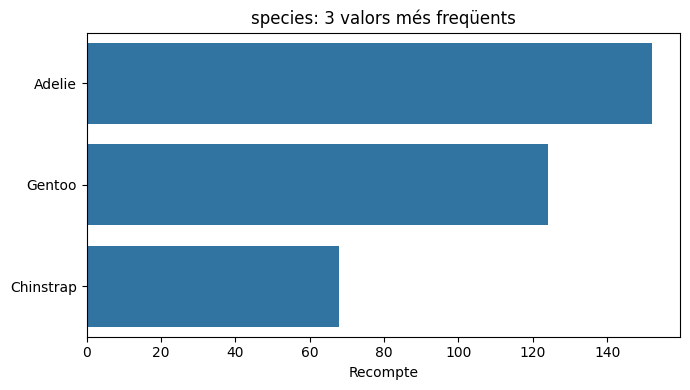

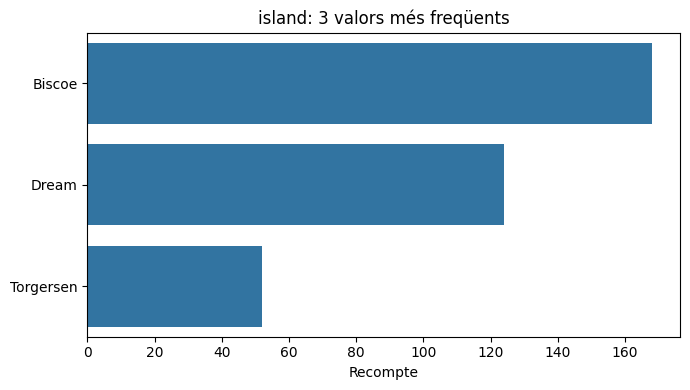

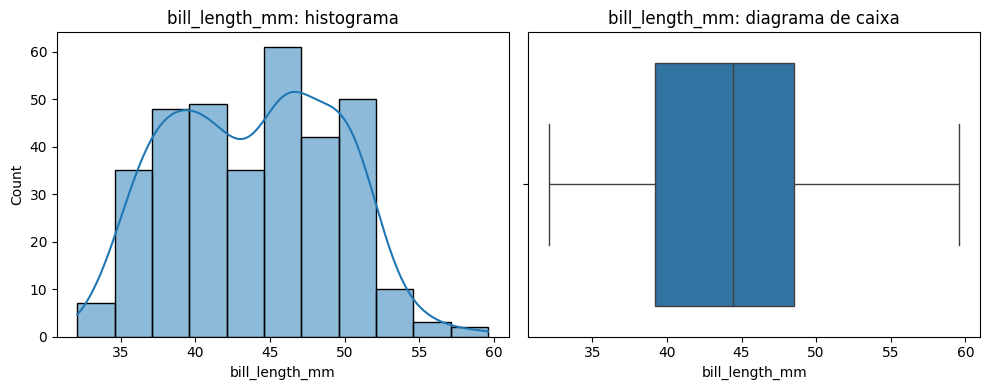

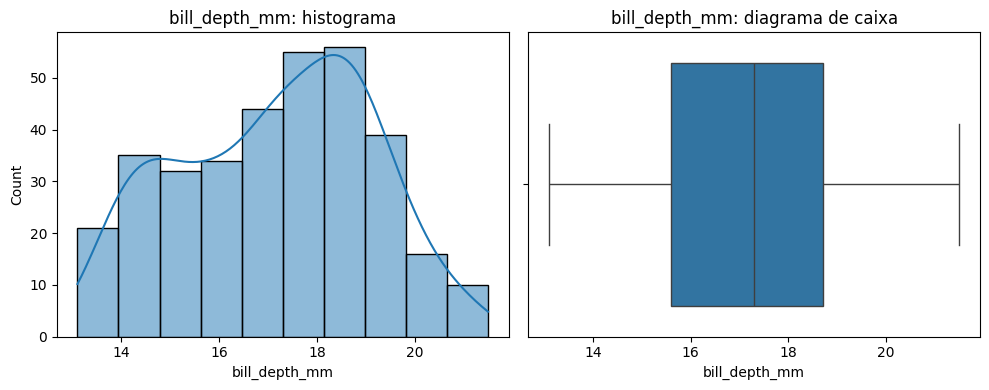

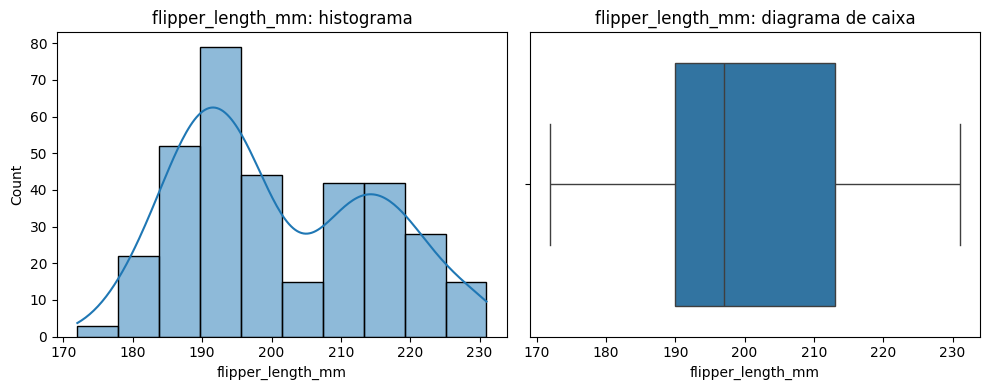

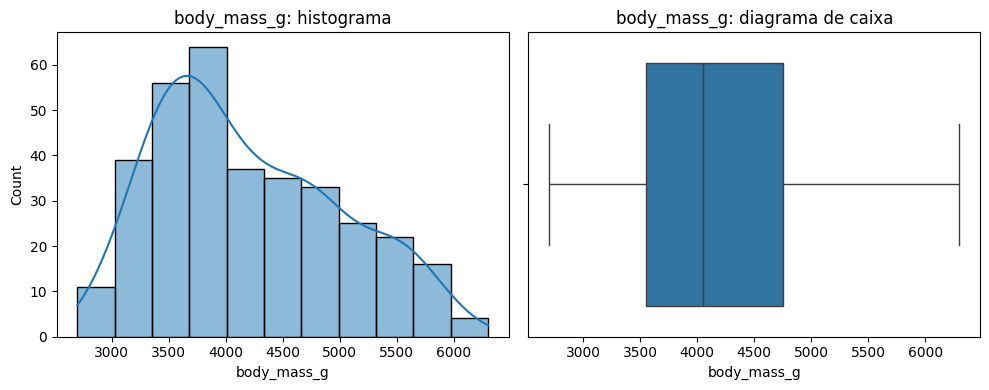

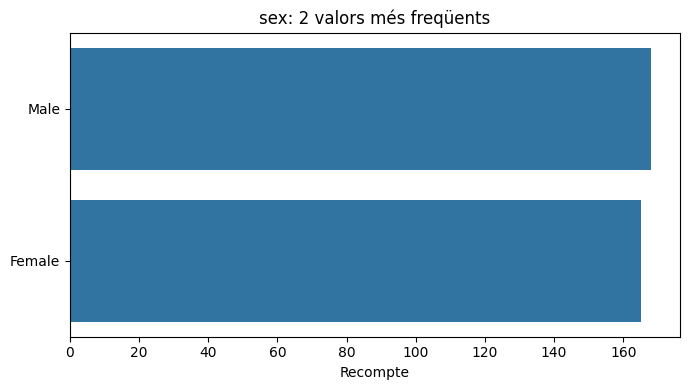

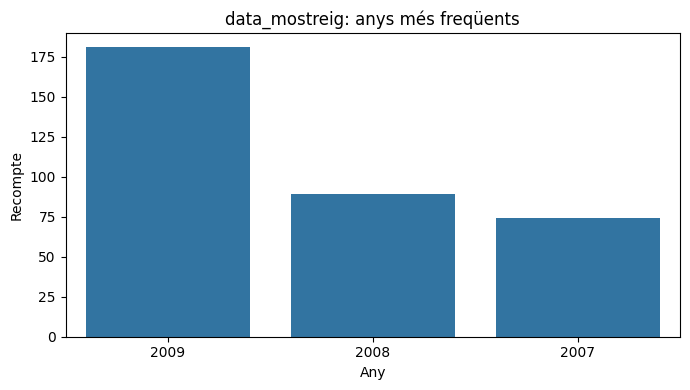

8 gràfics desats a 'grafics_penguins'


In [ ]:
def grafics_automatics(dades, carpeta="grafics", max_valors=10, mostrar=True):
    """Crea (i desa com a PNG) un gràfic adequat per a cada columna del DataFrame:
       - numèrica   -> histograma + diagrama de caixa
       - data       -> barres dels anys més freqüents
       - la resta   -> barres dels valors més freqüents (categòrica, text, booleà)"""
    os.makedirs(carpeta, exist_ok=True)
    fitxers = []
    for col in dades.columns:
        s = dades[col].dropna()
        if s.empty:
            print(f"Columna '{col}' buida: s'omet.")
            continue

        if pd.api.types.is_datetime64_any_dtype(s):
            fig, eix = plt.subplots(figsize=(7, 4))
            anys = s.dt.year.value_counts().head(max_valors)
            sns.barplot(x=anys.index.astype(str), y=anys.values, ax=eix)
            eix.set_title(f"{col}: anys més freqüents")
            eix.set_xlabel("Any"); eix.set_ylabel("Recompte")

        elif pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_bool_dtype(s):
            s = s.astype(float)
            fig, (eix1, eix2) = plt.subplots(1, 2, figsize=(10, 4))
            sns.histplot(s, kde=True, ax=eix1)
            eix1.set_title(f"{col}: histograma")
            sns.boxplot(x=s, ax=eix2)
            eix2.set_title(f"{col}: diagrama de caixa")

        else:
            fig, eix = plt.subplots(figsize=(7, 4))
            freq = s.astype(str).value_counts().head(max_valors)
            sns.barplot(x=freq.values, y=freq.index, ax=eix)
            eix.set_title(f"{col}: {len(freq)} valors més freqüents")
            eix.set_xlabel("Recompte"); eix.set_ylabel("")

        fig.tight_layout()
        ruta = os.path.join(carpeta, re.sub(r"\W+", "_", str(col)) + ".png")
        fig.savefig(ruta, dpi=100)
        fitxers.append(ruta)
        if mostrar:
            plt.show()
        plt.close(fig)
    print(f"{len(fitxers)} gràfics desats a '{carpeta}'")
    return fitxers

# ---- DEMOSTRACIÓ amb el conjunt de dades «penguins» de seaborn ----
try:
    pinguins = sns.load_dataset("penguins")
except Exception:
    generador = np.random.default_rng(0)
    n = 344
    pinguins = pd.DataFrame({
        "species": generador.choice(["Adelie", "Gentoo", "Chinstrap"], n, p=[.44, .36, .20]),
        "island": generador.choice(["Biscoe", "Dream", "Torgersen"], n),
        "bill_length_mm": generador.normal(44, 5.5, n),
        "bill_depth_mm": generador.normal(17, 2, n),
        "flipper_length_mm": generador.normal(200, 14, n),
        "body_mass_g": generador.normal(4200, 800, n),
        "sex": generador.choice(["Male", "Female"], n)})

pinguins["data_mostreig"] = pd.to_datetime(
    np.random.default_rng(1).choice(["2007-11-05", "2008-11-12", "2009-11-20", "2009-12-01"], len(pinguins)))

camins = grafics_automatics(pinguins, carpeta="grafics_penguins")

En aquest exercici he desenvolupat la funció grafics_automatics(), que rep un DataFrame, crea la carpeta de destinació i recorre totes les columnes una per una descartant els valors nuls i ometent les columnes buides. Per a cada columna, comprova el tipus de dada: si és de tipus data (is_datetime64_any_dtype), extreu els anys i dibuixa un gràfic de barres amb els més freqüents utilitzant sns.barplot(); si és numèrica i no booleana (is_numeric_dtype), crea una figura dividida en dos subgràfics amb un histograma i corba de densitat (sns.histplot) a l'esquerra i un diagrama de caixa (sns.boxplot) a la dreta; i per a la resta de variables categòriques o de text, dibuixa un gràfic de barres horitzontals amb els valors més repetits. Cada gràfic es desa automàticament en format PNG amb el nom de la columna netejat mitjançant re.sub(). Per posar la funció a prova, he carregat el dataset penguins de seaborn (amb un bloc try-except que el genera sintèticament si no hi ha connexió), hi he afegit una columna fictícia de dates de mostreig i he executat la funció per exportar tots els gràfics.

###**Exercici 2: Optimització de rutes (problema aplicat)**

🌍 Context: L'empresa no disposa d'un control fiable del quilometratge dels desplaçaments dels seus treballadors. Abans d'implementar un sistema avançat, es vol fer una prova pilot amb treballadors ubicats a Espanya.
Per a aquesta prova:

» Es treballa amb una matriu de distàncies entre ciutats.

» Es vol una solució simple, raonable i explicable.

» No es busca la ruta òptima, sinó una aproximació coherent.
Carrega l'arxiu matriu_distancies.xlsx a pandas de manera que les files i columnes siguin les ciutats i s'eliminin "Las Palmas de Gran Canaria" i "Palma".

Desenvolupa una funció que:

» Rebi: una ciutat d'origen i una ciutat de destinació.
» Retorni: l'ordre de les ciutats visitades (ruta) i la distància total recorreguda.

La ruta s'ha de construir seguint una estratègia senzilla: anar sempre a la ciutat no visitada més propera fins a arribar a la destinació.

In [ ]:
dist = pd.read_excel(matrius, sheet_name=0, index_col=0)
dist.index.name = dist.columns.name = None
dist = dist.drop(index=["Las Palmas de Gran Canaria", "Palma"],
                 columns=["Las Palmas de Gran Canaria", "Palma"])
print(f"Matriu: {dist.shape[0]} x {dist.shape[1]} ciutats")
print("Simètrica:", np.allclose(dist.fillna(0).values, dist.fillna(0).values.T),
      "| NaN només a la diagonal:", bool(dist.isna().sum().sum() == len(dist)))
display(dist.head(4))

alies = {"alacant": "Alicante", "l'hospitalet de llobregat": "Hospitalet de Llobregat"}
noms = {clau(c): c for c in dist.index}
noms.update({clau(k): v for k, v in alies.items()})

def ruta_veina_mes_propera(origen, desti, matriu=dist):
    """Retorna (llista de ciutats visitades, distància total en km)
       anant sempre a la ciutat no visitada més propera fins arribar al destí."""
    try:
        origen, desti = noms[clau(origen)], noms[clau(desti)]
    except KeyError as error:
        raise ValueError(f"Ciutat desconeguda: {error}. Opcions: {list(matriu.index)}")
    ruta, total, actual = [origen], 0, origen
    while actual != desti:
        pendents = matriu.loc[actual, [c for c in matriu.index if c not in ruta]]
        seguent = pendents.idxmin()
        total += pendents.min()
        ruta.append(seguent)
        actual = seguent
    return ruta, int(total)

for ori, des in [("Barcelona", "Sevilla"), ("Zaragoza", "Murcia"), ("Alacant", "Vigo"), ("Bilbao", "Bilbao")]:
    ruta, km = ruta_veina_mes_propera(ori, des)
    directa = dist.loc[noms[clau(ori)], noms[clau(des)]]
    print(f"{ori} -> {des}: {' -> '.join(ruta)}")
    print(f"   Distància de la ruta: {km} km | distància directa: {'0' if pd.isna(directa) else int(directa)} km\n")

Matriu: 13 x 13 ciutats
Simètrica: True | NaN només a la diagonal: True


,Barcelona,Valencia,Sevilla,Zaragoza,Málaga,Murcia,Bilbao,Alicante,Córdoba,Valladolid,Vigo,Gijón,Hospitalet de Llobregat
Barcelona,NaN,303.0,831.0,256.0,770.0,471.0,469.0,407.0,711.0,576.0,908.0,686.0,7.0
Valencia,303.0,NaN,541.0,246.0,468.0,177.0,473.0,125.0,421.0,441.0,766.0,632.0,297.0
Sevilla,831.0,541.0,NaN,646.0,158.0,433.0,703.0,495.0,121.0,486.0,588.0,685.0,824.0
Zaragoza,256.0,246.0,646.0,NaN,628.0,408.0,246.0,368.0,535.0,320.0,652.0,444.0,250.0


Barcelona -> Sevilla: Barcelona -> Hospitalet de Llobregat -> Zaragoza -> Valencia -> Alicante -> Murcia -> Córdoba -> Sevilla
   Distància de la ruta: 1138 km | distància directa: 831 km

Zaragoza -> Murcia: Zaragoza -> Valencia -> Alicante -> Murcia
   Distància de la ruta: 440 km | distància directa: 408 km

Alacant -> Vigo: Alicante -> Murcia -> Valencia -> Zaragoza -> Bilbao -> Gijón -> Valladolid -> Vigo
   Distància de la ruta: 1522 km | distància directa: 821 km

Bilbao -> Bilbao: Bilbao
   Distància de la ruta: 0 km | distància directa: 0 km



Finalment, he carregat l'arxiu matriu_distancies.xlsx configurant la primera columna com a índex i he eliminat tant de les files com de les columnes les ciutats de "Las Palmas de Gran Canaria" i "Palma", comprovant amb np.allclose() que la matriu resultant fos simètrica i que només tingués valors nuls a la diagonal. També he creat un diccionari de noms normalitzats i àlies (com "alacant" per "Alicante") per evitar errors en escriure les ciutats. Tot seguit, he programat la funció ruta_veina_mes_propera(), que rep una ciutat d'origen i una de destinació, inicialitza la llista de la ruta i la distància total a zero, i entra en un bucle while que s'executa fins que la ciutat actual coincideix amb la destinació. A cada iteració, la funció consulta a la matriu quines ciutats queden pendents de visitar, tria la que té la distància mínima amb .idxmin(), suma els quilòmetres amb .min(), l'afegeix a la llista de la ruta i avança fins a aquesta nova ciutat, retornant al final l'itinerari complet i la distància total. Per acabar, he provat la funció amb quatre trajectes d'exemple comparant la distància de la ruta calculada amb la distància directa entre l'origen i el destí.